<a href="https://colab.research.google.com/github/subbareddypullalacheruvu/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-/blob/main/notebooks/baseline_ulb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Kaggle download
import os
from getpass import getpass

os.environ['KAGGLE_USERNAME'] = input('Kaggle username: ')
os.environ['KAGGLE_KEY'] = getpass('Kaggle API key: ')

!kaggle datasets download -d mlg-ulb/creditcardfraud -p /content/data/ulb --unzip
!kaggle datasets download -d kartik2112/fraud-detection -p /content/data/sparkov --unzip

Kaggle username: Subbareddy_Subbz
Kaggle API key: ··········
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 261MB/s]

Dataset URL: https://www.kaggle.com/datasets/kartik2112/fraud-detection
License(s): CC0-1.0
100% 202M/202M [00:01<00:00, 203MB/s]



In [2]:
# 2. Clone the repo (already has split.py and utils.py inside it)
github_token = getpass('Paste your GitHub token: ')
repo_url = f'https://{github_token}@github.com/subbareddypullalacheruvu/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-.git'
!git clone {repo_url}

Paste your GitHub token: ··········
Cloning into 'Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 50 (delta 22), reused 14 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 316.46 KiB | 7.72 MiB/s, done.
Resolving deltas: 100% (22/22), done.


In [3]:
# 3. Move in, confirm, move data in
%cd Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-
!mv /content/data/ulb /content/data/sparkov data/


/content/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-


In [4]:
# 5. Regenerate the split (imports the already-written split.py from the repo)
import sys
sys.path.append('/content/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-')
from src.split import split_sparkov, split_ulb

sparkov_train, sparkov_test = split_sparkov()
ulb_train, ulb_test = split_ulb()

Train: 1,296,675 rows, from 2019-01-01 00:00:18 to 2020-06-21 12:13:37
Test:  555,719 rows, from 2020-06-21 12:14:25 to 2020-12-31 23:59:34
Train: 226,980 rows, from 0.0 to 145233.0
Test:  56,746 rows, from 145234.0 to 172792.0


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
import matplotlib.pyplot as plt

# Use every raw column except the label and the 'hour' column we added during EDA
# (hour is just derived from Time, not a real extra feature, so we leave it out here)
feature_cols = [c for c in ulb_train.columns if c not in ['Class', 'hour']]

X_train = ulb_train[feature_cols]
y_train = ulb_train['Class']

X_test = ulb_test[feature_cols]
y_test = ulb_test['Class']

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Features used:", feature_cols)

Train shape: (226980, 30) Test shape: (56746, 30)
Features used: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


## Train the model

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Model trained (on scaled features).")

Model trained (on scaled features).


## Score the model on the held-out test set

In [8]:
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

pr_auc = average_precision_score(y_test, y_pred_proba)
print(f"PR-AUC (test set): {pr_auc:.4f}")


PR-AUC (test set): 0.7306


This is the actual Week 4 deliverable number. A PR-AUC of 0.7306 is a strong result for a totally untuned baseline — a model with no real signal would score close to the test set's actual fraud rate (about 0.0018), so 0.73 means this simple model is already ranking fraud transactions well above legit ones most of the time. This is the number every later stage (Sparkov feature engineering, imbalance-handling strategies) needs to beat.

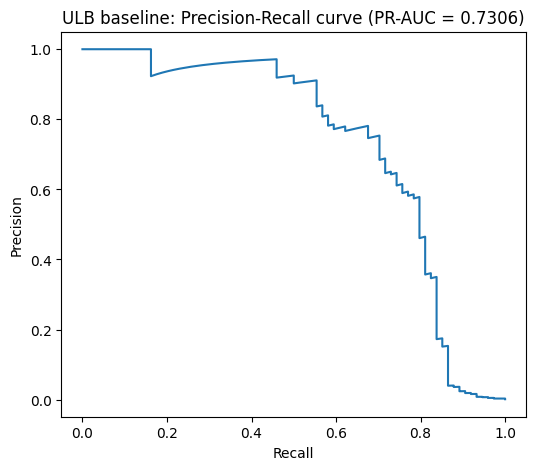

In [9]:
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'ULB baseline: Precision-Recall curve (PR-AUC = {pr_auc:.4f})')
plt.show()

This curve shows the tradeoff between catching fraud and raising false alarms. Precision stays above roughly 90% up to about 50–60% recall — meaning the model can catch a bit over half of all fraud cases while still being right almost every time it flags one. Past that point, precision drops sharply: pushing the model to catch more and more fraud (higher recall) means accepting a lot more false alarms. This is the classic tradeoff with imbalanced data, and it's also the target for later stages — Sparkov feature engineering and imbalance-handling strategies (Stage 6/7) should aim to keep precision higher even as recall increases, not just improve the single PR-AUC number.

In [10]:
from sklearn.metrics import fbeta_score, matthews_corrcoef

# Convert probabilities into actual fraud/not-fraud predictions using the default 0.5 cutoff
y_pred = (y_pred_proba >= 0.5).astype(int)

f2 = fbeta_score(y_test, y_pred, beta=2)
mcc = matthews_corrcoef(y_test, y_pred)

print(f"PR-AUC: {pr_auc:.4f}")
print(f"F2:     {f2:.4f}")
print(f"MCC:    {mcc:.4f}")

PR-AUC: 0.7306
F2:     0.6012
MCC:    0.7102


MCC of 0.71 is a good result — it ranges from -1 (always wrong) to 1 (perfect), with 0 meaning no better than random guessing, so 0.71 says the model's predictions line up well with the actual fraud labels overall, even accounting for the class imbalance. F2 of 0.60 is more middling, and that's expected: F2 weights catching fraud (recall) more heavily than avoiding false alarms, and the precision-recall curve above already showed that pushing past ~50–60% recall costs a lot of precision. Together, these three numbers (PR-AUC 0.7306, F2 0.6012, MCC 0.7102) are the baseline that later stages need to improve on.

In [11]:
import json

baseline_results = {
    "stage": "Stage 5 - naive baseline",
    "dataset": "ULB",
    "model": "Logistic Regression (default params, scaled features, no resampling/weighting)",
    "pr_auc": pr_auc,
    "f2": f2,
    "mcc": mcc,
}

with open("results/stage5_ulb_baseline.json", "w") as f:
    json.dump(baseline_results, f, indent=2)

print("Saved to results/stage5_ulb_baseline.json")


Saved to results/stage5_ulb_baseline.json


In [14]:
!git add results/stage5_ulb_baseline.json
!git commit -m "Add Stage 5 ULB baseline results (PR-AUC/F2/MCC)"
!git push

[main 86fd794] Add Stage 5 ULB baseline results (PR-AUC/F2/MCC)
 1 file changed, 8 insertions(+)
 create mode 100644 results/stage5_ulb_baseline.json
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 585 bytes | 585.00 KiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/subbareddypullalacheruvu/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-.git
   26a67ec..86fd794  main -> main


## Summary — Stage 5 naive baseline (ULB)

A plain Logistic Regression, trained on the raw ULB features (Time, V1–V28, Amount) with no resampling, no class weighting, and no engineered features — just standard scaling so the model could actually converge. This is meant to be the simplest reasonable starting point, not a tuned model.

Result: PR-AUC = 0.7306, F2 = 0.6012, MCC = 0.7102, all on the held-out test set. For context, a model with no real signal would score close to the test set's actual fraud rate (~0.0018) on PR-AUC, so this baseline is already picking up meaningful signal, mainly from the handful of V columns the EDA correlation check flagged earlier (V17, V14, V12, V10). MCC being reasonably high (0.71) backs this up — it accounts for all four prediction outcomes and isn't skewed by the class imbalance the way plain accuracy would be. F2 (0.60) is lower because it weights catching fraud (recall) more heavily than avoiding false alarms, and the precision-recall curve explains why: precision holds above ~90% only up to about 50–60% recall, then drops sharply as recall pushes higher — a textbook imbalanced-classification tradeoff, and exactly the tradeoff F2 is measuring.

This baseline (PR-AUC 0.7306, F2 0.6012, MCC 0.7102) is the set of numbers every later stage — Sparkov feature engineering, imbalance-handling strategies — needs to beat. Results saved to results/stage5_ulb_baseline.json for direct comparison in later stages.